# Stage 2 - Data Understanding and Preparation
## E-Commerce Shipping Prediction: **Delivered vs Delayed**

**Problem scope.** The model answers one binary question: *will an order be
**Delivered** (1) or **Delayed** (0)?*

The raw file also contains `Returned` orders. Returns are a different business
process (reverse logistics), so they are **removed completely** at the first
step. Nothing after that step (EDA, features, splits, models, evaluation, API)
sees a Returned order.

This notebook explains the data and the preparation decisions. The
authoritative, reproducible implementation is `mlops_pipeline/data_stage.py`
(run `python scripts/run_end_to_end_pipeline.py` first).

In [1]:
from pathlib import Path
import sys

# Locate the project root (the folder containing mlops_pipeline/) from any notebook folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "mlops_pipeline").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FEATURE_STORE = ROOT / "artifacts" / "feature_store"
REPORTS = ROOT / "artifacts" / "reports"
FIGURES = ROOT / "artifacts" / "notebook_figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\Vivek Kumar Singh\Downloads\E-Commerce-Shipping-Prediction-main\E-Commerce-Shipping-Prediction-main


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

from mlops_pipeline.config import (
    TARGET_COLUMN, TARGET_OUTCOMES, TARGET_MAP, OUT_OF_SCOPE_OUTCOMES, FEATURE_COLUMNS,
)

source = pd.read_csv(ROOT / "50K Records.csv")
print("Source shape:", source.shape)
source.head()

Source shape: (50000, 10)


,Order_ID,Customer_Region,Product_Category,Order_Date,Ship_Date,Delivery_Date,Shipping_Mode,Shipping_Cost,Delivery_Status,Delivery_Days
0,OR10000,West,Home,05-12-2024,5/16/2024,5/26/2024,Standard,122,Delivered,10
1,OR10001,Central,Home,4/19/2025,4/24/2025,4/26/2025,Standard,143,Delivered,2
2,OR10002,East,Home,07-02-2025,07-04-2025,07-11-2025,Standard,107,Delayed,7
3,OR10003,Central,Grocery,10-04-2025,10-08-2025,10/16/2025,Standard,145,Delayed,8
4,OR10004,Central,Sports,10/31/2023,11-02-2023,11-07-2023,Standard,121,Delivered,5


### 1. Outcomes in the source file (before scoping)

In [3]:
source[TARGET_COLUMN].value_counts()

Delivery_Status
Delivered    40062
Delayed       7505
Returned      2433
Name: count, dtype: int64

### 2. Scope decision - remove `Returned`

Only `Delivered` and `Delayed` are kept. The removed row count is recorded so
the decision is auditable.

In [4]:
df = source[source[TARGET_COLUMN].isin(TARGET_OUTCOMES)].reset_index(drop=True)
removed = len(source) - len(df)

assert set(df[TARGET_COLUMN]) == set(TARGET_OUTCOMES)
assert not df[TARGET_COLUMN].isin(OUT_OF_SCOPE_OUTCOMES).any()

df["target"] = df[TARGET_COLUMN].map(TARGET_MAP)   # Delivered=1, Delayed=0
print(f"Source rows: {len(source):,}")
print(f"Removed (Returned): {removed:,}")
print(f"Rows in scope: {len(df):,}")
print("Target map:", TARGET_MAP)
df[TARGET_COLUMN].value_counts()

Source rows: 50,000
Removed (Returned): 2,433
Rows in scope: 47,567
Target map: {'Delivered': 1, 'Delayed': 0}


Delivery_Status
Delivered    40062
Delayed       7505
Name: count, dtype: int64

### 3. Data quality checks (on the in-scope rows)

In [5]:
dates = {c: pd.to_datetime(df[c], format="mixed", errors="coerce")
         for c in ["Order_Date", "Ship_Date", "Delivery_Date"]}
quality = {
    "missing_values": int(df.isna().sum().sum()),
    "duplicate_order_ids": int(df["Order_ID"].duplicated().sum()),
    "invalid_dates": {c: int(s.isna().sum()) for c, s in dates.items()},
    "order_after_ship": int((dates["Order_Date"] > dates["Ship_Date"]).sum()),
    "ship_after_delivery": int((dates["Ship_Date"] > dates["Delivery_Date"]).sum()),
    "negative_shipping_cost": int((df["Shipping_Cost"] < 0).sum()),
}
quality

{'missing_values': 0,
 'duplicate_order_ids': 0,
 'invalid_dates': {'Order_Date': 0, 'Ship_Date': 0, 'Delivery_Date': 0},
 'order_after_ship': 0,
 'ship_after_delivery': 0,
 'negative_shipping_cost': 0}

### 4. Target balance - Delivered vs Delayed

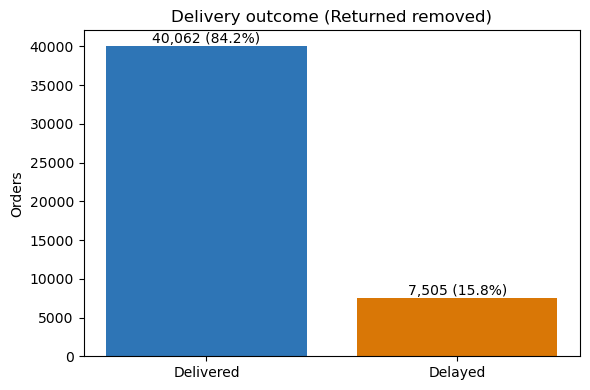

Delayed share: 15.78% -> class imbalance, so accuracy alone is misleading.


In [6]:
counts = df[TARGET_COLUMN].value_counts().reindex(["Delivered", "Delayed"])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=["#2E75B6", "#D97706"])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in counts.values])
ax.set_title("Delivery outcome (Returned removed)")
ax.set_ylabel("Orders")
fig.tight_layout(); fig.savefig(FIGURES / "target_balance.png", dpi=150); plt.show()
print(f"Delayed share: {(df['target'] == 0).mean():.2%} -> class imbalance, so accuracy alone is misleading.")

### 5. Does any order-time attribute separate Delayed from Delivered?

For each categorical predictor we show the delay rate per category and a
chi-square test of independence against the binary target.

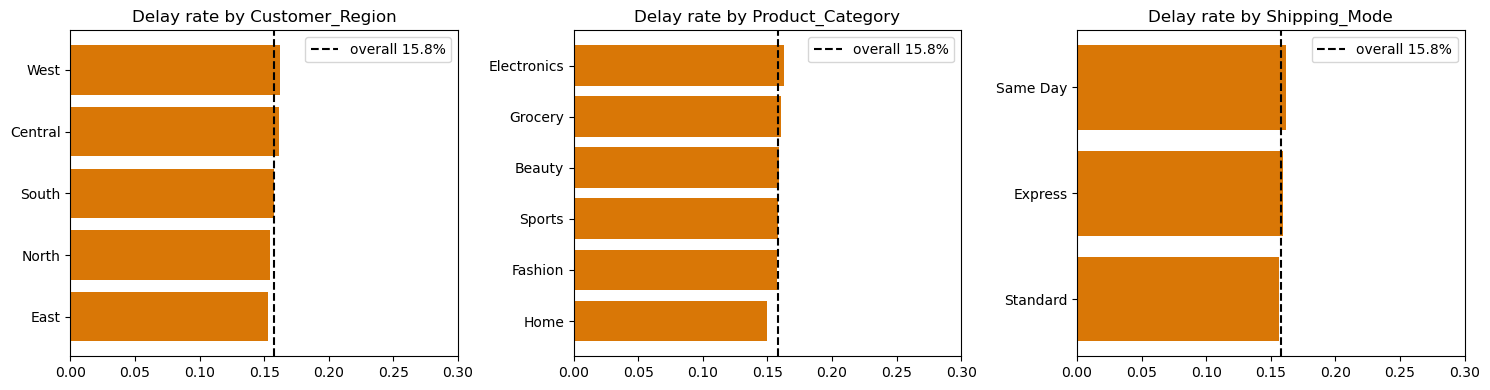

,feature,chi2,dof,p_value
0,Customer_Region,4.46,4,0.3472
1,Product_Category,6.23,5,0.2846
2,Shipping_Mode,1.08,2,0.5833


In [7]:
overall = (df["target"] == 0).mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rows = []
for ax, col in zip(axes, ["Customer_Region", "Product_Category", "Shipping_Mode"]):
    rate = df.groupby(col)["target"].apply(lambda s: (s == 0).mean()).sort_values()
    ax.barh(rate.index, rate.values, color="#D97706")
    ax.axvline(overall, color="black", linestyle="--", label=f"overall {overall:.1%}")
    ax.set_title(f"Delay rate by {col}"); ax.set_xlim(0, max(0.3, rate.max() * 1.2)); ax.legend()
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[col], df["target"]))
    rows.append({"feature": col, "chi2": round(chi2, 2), "dof": dof, "p_value": round(p, 4)})
fig.tight_layout(); fig.savefig(FIGURES / "delay_rate_by_category.png", dpi=150); plt.show()
pd.DataFrame(rows)

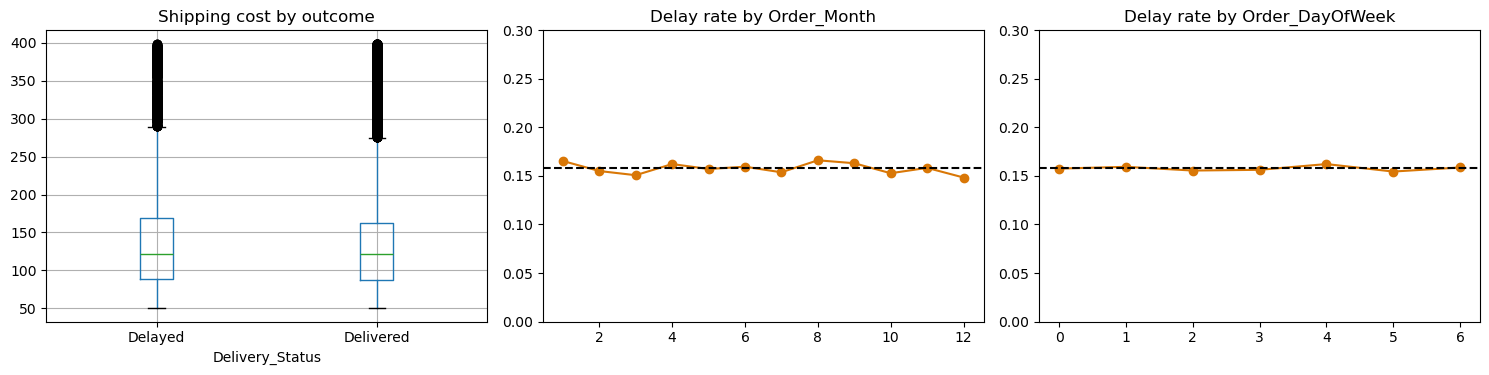

In [8]:
order_dates = dates["Order_Date"]
df["Order_Month"] = order_dates.dt.month
df["Order_DayOfWeek"] = order_dates.dt.dayofweek

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df.boxplot(column="Shipping_Cost", by=TARGET_COLUMN, ax=axes[0]); axes[0].set_title("Shipping cost by outcome")
for ax, col in zip(axes[1:], ["Order_Month", "Order_DayOfWeek"]):
    rate = df.groupby(col)["target"].apply(lambda s: (s == 0).mean())
    ax.plot(rate.index, rate.values, marker="o", color="#D97706")
    ax.axhline(overall, color="black", linestyle="--"); ax.set_title(f"Delay rate by {col}"); ax.set_ylim(0, 0.3)
plt.suptitle(""); fig.tight_layout(); fig.savefig(FIGURES / "numeric_and_calendar.png", dpi=150); plt.show()

**Observation.** Delay rates are almost flat across every category, month,
weekday, and cost level, and the chi-square tests do not show strong
dependence. This is an early warning that order-time attributes carry little
signal for Delivered vs Delayed.

### 6. Leakage review - which columns may be used?

The prediction is made **when the order is placed**. Anything known only later
is excluded:

| Column | Decision | Reason |
|---|---|---|
| `Ship_Date`, `Delivery_Date` | excluded | known only after shipping/delivery |
| `Delivery_Days` | excluded | computed from post-outcome dates |
| `Cost_per_Day` | excluded | divides by `Delivery_Days` |
| `Order_ID` | excluded | identifier |
| `Delivery_Status` | target | Delivered=1, Delayed=0 |

In [9]:
print("Model features:", FEATURE_COLUMNS)

Model features: ['Customer_Region', 'Product_Category', 'Shipping_Mode', 'Shipping_Cost', 'Order_Month', 'Order_DayOfWeek']


### 7. Prepared feature store (produced by the pipeline)

The pipeline applies the same scope filter, builds the features above, makes a
stratified 60/20/20 train/validation/test split, and fits the scaler on
training rows only. We verify that it matches this notebook.

In [10]:
import json
manifest = json.loads((FEATURE_STORE / "feature_manifest.json").read_text(encoding="utf-8"))
print("Scope filter:", json.dumps(manifest["scope_filter"], indent=2))
print("Split rows:", manifest["split_rows"])

y_all = pd.concat([pd.read_csv(FEATURE_STORE / f"y_{s}.csv") for s in ["train", "validation", "test"]])
assert list(y_all.columns) == ["binary_target"]
assert sorted(y_all["binary_target"].unique()) == [0, 1]
assert len(y_all) == len(df) and manifest["scope_filter"]["rows_removed"] == removed
print("Feature store is consistent with this notebook: binary target only, no Returned rows.")

Scope filter: {
  "kept_outcomes": [
    "Delivered",
    "Delayed"
  ],
  "reason": "Returned orders are outside the project scope; the model predicts Delivered vs Delayed only.",
  "removed_outcomes": {
    "Returned": 2433
  },
  "rows_in_scope": 47567,
  "rows_removed": 2433,
  "source_rows": 50000
}
Split rows: {'test': 9514, 'train': 28539, 'validation': 9514}
Feature store is consistent with this notebook: binary target only, no Returned rows.


### Summary

* 2,433 Returned orders removed; 47,567 orders modeled (Delivered 84.2%, Delayed 15.8%).
* Data quality is clean (no blocking defects).
* Only order-time features are used; post-outcome fields are excluded to prevent leakage.
* EDA shows almost no visible relationship between features and delay, so expectations for model performance should be modest.

Next: `modelling.ipynb/Models.ipynb`.